In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA770171/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,Mating_type,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,sample_type,SRA.Study,strain
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,SRR16320307,AMPLICON,598,85613022,PRJNA770171,SAMN22210743,Metagenome or environmental,48647819,MEDICAL UNIVERSITY OF LODZ,missing,⋯,622,human saliva metagenome,ILLUMINA,2021-12-16T00:00:00Z,2021-10-13T17:23:00Z,1,S_27,tissue sample,SRP341269,microbial
2,SRR16320308,AMPLICON,598,120629505,PRJNA770171,SAMN22210730,Metagenome or environmental,68388525,MEDICAL UNIVERSITY OF LODZ,missing,⋯,489,human saliva metagenome,ILLUMINA,2021-12-16T00:00:00Z,2021-10-13T17:23:00Z,1,S_14,tissue sample,SRP341269,microbial
3,SRR16320309,AMPLICON,598,143043681,PRJNA770171,SAMN22210745,Metagenome or environmental,81222631,MEDICAL UNIVERSITY OF LODZ,missing,⋯,472,human saliva metagenome,ILLUMINA,2021-12-16T00:00:00Z,2021-10-13T17:23:00Z,1,S_29,tissue sample,SRP341269,microbial
4,SRR16320310,AMPLICON,597,73630620,PRJNA770171,SAMN22210733,Metagenome or environmental,41635634,MEDICAL UNIVERSITY OF LODZ,missing,⋯,471,human saliva metagenome,ILLUMINA,2021-12-16T00:00:00Z,2021-10-13T17:23:00Z,1,S_17,tissue sample,SRP341269,microbial
5,SRR16320311,AMPLICON,598,132908753,PRJNA770171,SAMN22210746,Metagenome or environmental,76268009,MEDICAL UNIVERSITY OF LODZ,missing,⋯,488,human saliva metagenome,ILLUMINA,2021-12-16T00:00:00Z,2021-10-13T17:23:00Z,1,S_30,tissue sample,SRP341269,microbial
6,SRR16320312,AMPLICON,598,56949438,PRJNA770171,SAMN22210736,Metagenome or environmental,32878170,MEDICAL UNIVERSITY OF LODZ,missing,⋯,487,human saliva metagenome,ILLUMINA,2021-12-16T00:00:00Z,2021-10-13T17:23:00Z,1,S_20,tissue sample,SRP341269,microbial


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "HOST"                           "Instrument"                    
[21] "isolate"                        "lat_lon"                       
[23] "Library.Name"                   "LibraryLayout"                 
[25] "LibrarySelection"               "LibrarySource"                 
[27] "Mating_type"                    "Organism"                      
[29] "Platform"                       "ReleaseDate"                   
[31] "create_date"                    "version"                       
[33] "Sample.Name"                    "sample_type"                   
[35] "SRA.Study"                      "strain"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V3-V4',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$isolate,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = "Evaluation of Changes to the Oral Microbiome Based on 16S rRNA Sequencing among Children Treated for Cancer",
    Disease_study = "YES",
    Status = 'cancer',
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 40
[1] 40


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<chr>,<chr>
1,PRJNA770171,SRR16320307,S_27,NA,NA,NA,V3-V4,ILLUMINA,Poland,saliva,2021-12-16T00:00:00Z,NA,Evaluation of Changes to the Oral Microbiome Based on 16S rRNA Sequencing among Children Treated for Cancer,YES,cancer,NO
2,PRJNA770171,SRR16320308,S_14,NA,NA,NA,V3-V4,ILLUMINA,Poland,saliva,2021-12-16T00:00:00Z,NA,Evaluation of Changes to the Oral Microbiome Based on 16S rRNA Sequencing among Children Treated for Cancer,YES,cancer,NO
3,PRJNA770171,SRR16320309,S_29,NA,NA,NA,V3-V4,ILLUMINA,Poland,saliva,2021-12-16T00:00:00Z,NA,Evaluation of Changes to the Oral Microbiome Based on 16S rRNA Sequencing among Children Treated for Cancer,YES,cancer,NO
4,PRJNA770171,SRR16320310,S_17,NA,NA,NA,V3-V4,ILLUMINA,Poland,saliva,2021-12-16T00:00:00Z,NA,Evaluation of Changes to the Oral Microbiome Based on 16S rRNA Sequencing among Children Treated for Cancer,YES,cancer,NO
5,PRJNA770171,SRR16320311,S_30,NA,NA,NA,V3-V4,ILLUMINA,Poland,saliva,2021-12-16T00:00:00Z,NA,Evaluation of Changes to the Oral Microbiome Based on 16S rRNA Sequencing among Children Treated for Cancer,YES,cancer,NO
6,PRJNA770171,SRR16320312,S_20,NA,NA,NA,V3-V4,ILLUMINA,Poland,saliva,2021-12-16T00:00:00Z,NA,Evaluation of Changes to the Oral Microbiome Based on 16S rRNA Sequencing among Children Treated for Cancer,YES,cancer,NO


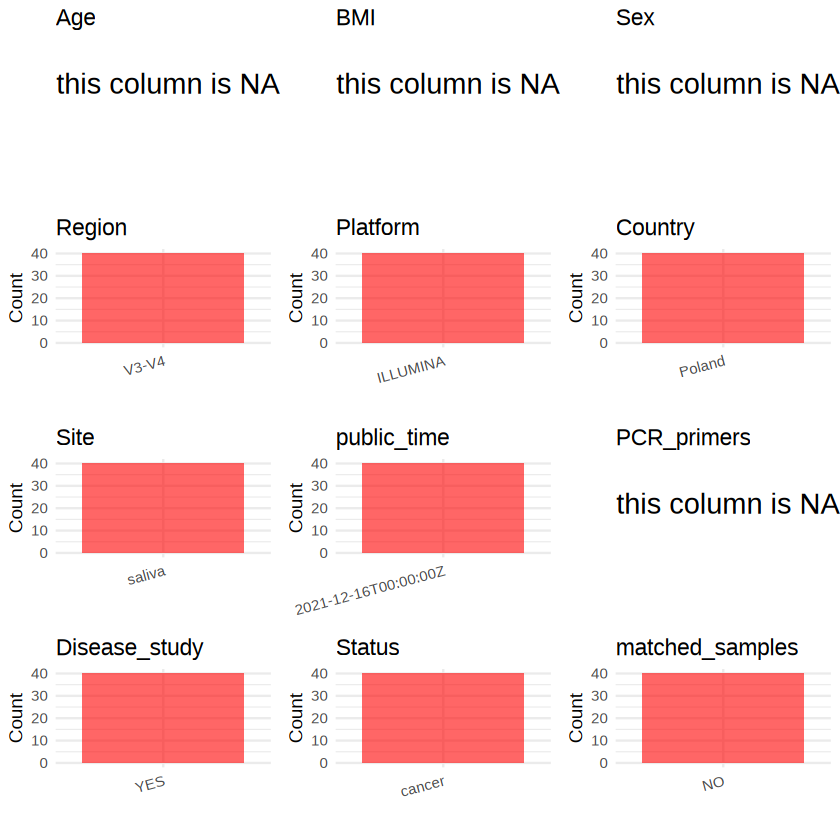

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA770171/metadata.csv", quote = T)